In [1]:
from pathlib import Path
import sys
import json
import numpy as np

project_root = Path.cwd().resolve()
if not (project_root / "src" / "KNN.py").is_file():
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from dataprep import prepare_data, RAW_SIGNAL_NAMES
from KNN import KNNClassifier, cross_validate_knn, make_group_folds
from KNN import confusion_matrix, balanced_accuracy_score

# Selecao de k: somente as 7.352 amostras do treino oficial.
# A padronizacao sera ajustada dentro de cada fold pelo KNN.py.
dados = prepare_data(
    representation="raw", standardize=False,
    split_seed=42, validation_subject_count=4,
)
X_desenvolvimento = np.vstack((dados.X_train, dados.X_validation))
y_desenvolvimento = np.concatenate((dados.y_train, dados.y_validation))
sujeitos_desenvolvimento = np.concatenate((dados.subjects_train, dados.subjects_validation))
k_values = list(range(1, 32, 2))
n_splits = 5
cv_seed = 42

resultado_busca = cross_validate_knn(
    X_desenvolvimento, y_desenvolvimento, sujeitos_desenvolvimento,
    k_values=k_values, n_splits=n_splits, seed=cv_seed, standardize=True,
)
resultados_k = [
    {
        "k": k,
        "acuracias_balanceadas_folds": resultado_busca.fold_scores[i].tolist(),
        "media_acuracia_balanceada": float(resultado_busca.mean_scores[i]),
        "desvio_padrao": float(resultado_busca.standard_deviations[i]),
    }
    for i, k in enumerate(resultado_busca.k_values)
]
melhores_hiperparametros = {"n_neighbors": resultado_busca.best_k}
melhor_resultado = next(r for r in resultados_k if r["k"] == resultado_busca.best_k)
folds = make_group_folds(sujeitos_desenvolvimento, n_splits=n_splits, seed=cv_seed)
divisao_folds = [
    {
        "fold": i,
        "sujeitos_treino": np.unique(sujeitos_desenvolvimento[treino]).tolist(),
        "sujeitos_validacao": np.unique(sujeitos_desenvolvimento[validacao]).tolist(),
        "amostras_treino": len(treino),
        "amostras_validacao": len(validacao),
    }
    for i, (treino, validacao) in enumerate(folds, 1)
]
pasta_resultados = project_root / "results"
pasta_resultados.mkdir(parents=True, exist_ok=True)
(pasta_resultados / "knn_2b_busca.json").write_text(
    json.dumps({
        "metrica": "acuracia_balanceada", "n_splits": n_splits,
        "cv_seed": cv_seed, "folds": divisao_folds,
        "resultados": resultados_k, "melhor_k": resultado_busca.best_k,
    }, indent=2) + "\n", encoding="utf-8",
)
print("Amostras desenvolvimento / teste:", len(y_desenvolvimento), len(dados.y_test))
print(" k | " + " | ".join(f"fold {i}" for i in range(1, n_splits + 1)) + " | media | desvio padrao")
for r in resultados_k:
    valores = " | ".join(f"{v:.6f}" for v in r["acuracias_balanceadas_folds"])
    print(f"{r['k']:2d} | {valores} | {r['media_acuracia_balanceada']:.6f} | {r['desvio_padrao']:.6f}")
print("Melhores hiperparametros:", melhores_hiperparametros)
print("Melhor media na validacao cruzada:", melhor_resultado["media_acuracia_balanceada"])


Amostras desenvolvimento / teste: 7352 2947
 k | fold 1 | fold 2 | fold 3 | fold 4 | fold 5 | media | desvio padrao
 1 | 0.685201 | 0.678870 | 0.851491 | 0.751010 | 0.741900 | 0.741694 | 0.062097
 3 | 0.656314 | 0.663928 | 0.827870 | 0.710062 | 0.699055 | 0.711446 | 0.061656
 5 | 0.626525 | 0.633179 | 0.803644 | 0.687009 | 0.670513 | 0.684174 | 0.063862
 7 | 0.602660 | 0.592129 | 0.782052 | 0.663240 | 0.645156 | 0.657048 | 0.067791
 9 | 0.584619 | 0.578751 | 0.748441 | 0.643851 | 0.620172 | 0.635167 | 0.061431
11 | 0.566659 | 0.564283 | 0.728469 | 0.628318 | 0.599384 | 0.617423 | 0.060293
13 | 0.556840 | 0.545575 | 0.715734 | 0.617614 | 0.585754 | 0.604303 | 0.061057
15 | 0.545305 | 0.541573 | 0.702898 | 0.607463 | 0.579265 | 0.595301 | 0.058938
17 | 0.533520 | 0.535442 | 0.696042 | 0.599486 | 0.569253 | 0.586749 | 0.059798
19 | 0.503614 | 0.530729 | 0.683403 | 0.596307 | 0.553981 | 0.573607 | 0.062759
21 | 0.497503 | 0.526242 | 0.672271 | 0.586233 | 0.542550 | 0.564960 | 0.060860
23 |

In [2]:
# Ajuste final com todo o treino oficial, usando o k escolhido na validacao cruzada.
modelo_final = KNNClassifier(**melhores_hiperparametros, standardize=True)
modelo_final.fit(X_desenvolvimento, y_desenvolvimento)
y_pred_teste = modelo_final.predict(dados.X_test)
matriz_confusao_teste = confusion_matrix(
    dados.y_test, y_pred_teste, labels=modelo_final.classes_,
)
metricas_finais = {
    "hiperparametros": melhores_hiperparametros,
    "representacao": "raw",
    "sinais": list(RAW_SIGNAL_NAMES),
    "numero_atributos": dados.X_train.shape[1],
    "divisao": "teste_oficial_uci_har",
    "metrica_selecao": "acuracia_balanceada",
    "media_validacao_cruzada": melhor_resultado["media_acuracia_balanceada"],
    "desvio_padrao_validacao_cruzada": melhor_resultado["desvio_padrao"],
    "sujeitos_treino_final": np.unique(sujeitos_desenvolvimento).tolist(),
    "sujeitos_teste": list(dados.subject_split.test),
    "amostras_treino_final": len(y_desenvolvimento),
    "amostras_teste": len(dados.y_test),
    "acuracia_teste": float(np.mean(y_pred_teste == dados.y_test)),
    "acuracia_balanceada_teste": balanced_accuracy_score(dados.y_test, y_pred_teste),
    "classes": modelo_final.classes_.tolist(),
    "nomes_classes": list(dados.class_names),
    "matriz_confusao_teste": matriz_confusao_teste.tolist(),
}

# KNN armazena as amostras de referencia; salva tambem a padronizacao final.
np.savez_compressed(
    pasta_resultados / "knn_2b_final.npz",
    X_train=modelo_final.X_train_, y_encoded=modelo_final.y_encoded_,
    classes=modelo_final.classes_,
    train_squared_norms=modelo_final.train_squared_norms_,
    mean=modelo_final.mean_, scale=modelo_final.scale_,
    n_neighbors=modelo_final.n_neighbors, standardize=modelo_final.standardize,
    feature_names=np.asarray(dados.feature_names),
    train_subjects=np.unique(sujeitos_desenvolvimento),
    test_subjects=np.asarray(dados.subject_split.test),
)
(pasta_resultados / "knn_2b_metricas.json").write_text(
    json.dumps(metricas_finais, indent=2) + "\n", encoding="utf-8",
)
# Resumo legivel; os resultados completos continuam salvos no JSON.
nomes_atividades = {
    1: "Caminhar", 2: "Subir escadas", 3: "Descer escadas",
    4: "Sentado", 5: "Em pe", 6: "Deitado",
}
acertos_por_classe = np.diag(matriz_confusao_teste)
totais_por_classe = matriz_confusao_teste.sum(axis=1)
print("KNN 2b - ACC/GYR: 6 sinais x 128 valores = 768 atributos")
print(f"Hiperparametro escolhido: k = {melhores_hiperparametros['n_neighbors']}")
print("Configuracao: distancia euclidiana | voto majoritario | padronizacao ativa")
print(f"Selecao: validacao cruzada com {n_splits} folds por sujeito")
print(f"Acuracia balanceada na validacao: {100 * metricas_finais['media_validacao_cruzada']:.2f}%"
      f" | desvio-padrao: {100 * metricas_finais['desvio_padrao_validacao_cruzada']:.2f} pontos percentuais")
print(f"Treino final: {metricas_finais['amostras_treino_final']} amostras"
      f" | Teste oficial: {metricas_finais['amostras_teste']} amostras")
print()
print("RESULTADOS NO TESTE")
print(f"Acertos totais: {int(acertos_por_classe.sum())} / {metricas_finais['amostras_teste']}"
      f" | Erros: {int(matriz_confusao_teste.sum() - acertos_por_classe.sum())}")
print(f"Acuracia: {100 * metricas_finais['acuracia_teste']:.2f}%"
      f" | Acuracia balanceada: {100 * metricas_finais['acuracia_balanceada_teste']:.2f}%")
print()
print(f"{'Classe real':<22} {'Acertos':>8} {'Total':>8} {'Erros':>8} {'Recall':>10}")
print("-" * 60)
for classe, acertos, total in zip(metricas_finais['classes'], acertos_por_classe, totais_por_classe):
    nome = f"{classe} - {nomes_atividades[classe]}"
    recall = 100 * acertos / total if total else 0.0
    print(f"{nome:<22} {acertos:>8d} {total:>8d} {total - acertos:>8d} {recall:>9.2f}%")
print("Recall = percentual de acertos entre as amostras reais de cada classe.")


KNN 2b - ACC/GYR: 6 sinais x 128 valores = 768 atributos
Hiperparametro escolhido: k = 1
Configuracao: distancia euclidiana | voto majoritario | padronizacao ativa
Selecao: validacao cruzada com 5 folds por sujeito
Acuracia balanceada na validacao: 74.17% | desvio-padrao: 6.21 pontos percentuais
Treino final: 7352 amostras | Teste oficial: 2947 amostras

RESULTADOS NO TESTE
Acertos totais: 2139 / 2947 | Erros: 808
Acuracia: 72.58% | Acuracia balanceada: 71.00%

Classe real             Acertos    Total    Erros     Recall
------------------------------------------------------------
1 - Caminhar                334      496      162     67.34%
2 - Subir escadas           340      471      131     72.19%
3 - Descer escadas          117      420      303     27.86%
4 - Sentado                 394      491       97     80.24%
5 - Em pe                   417      532      115     78.38%
6 - Deitado                 537      537        0    100.00%
Recall = percentual de acertos entre as amostr

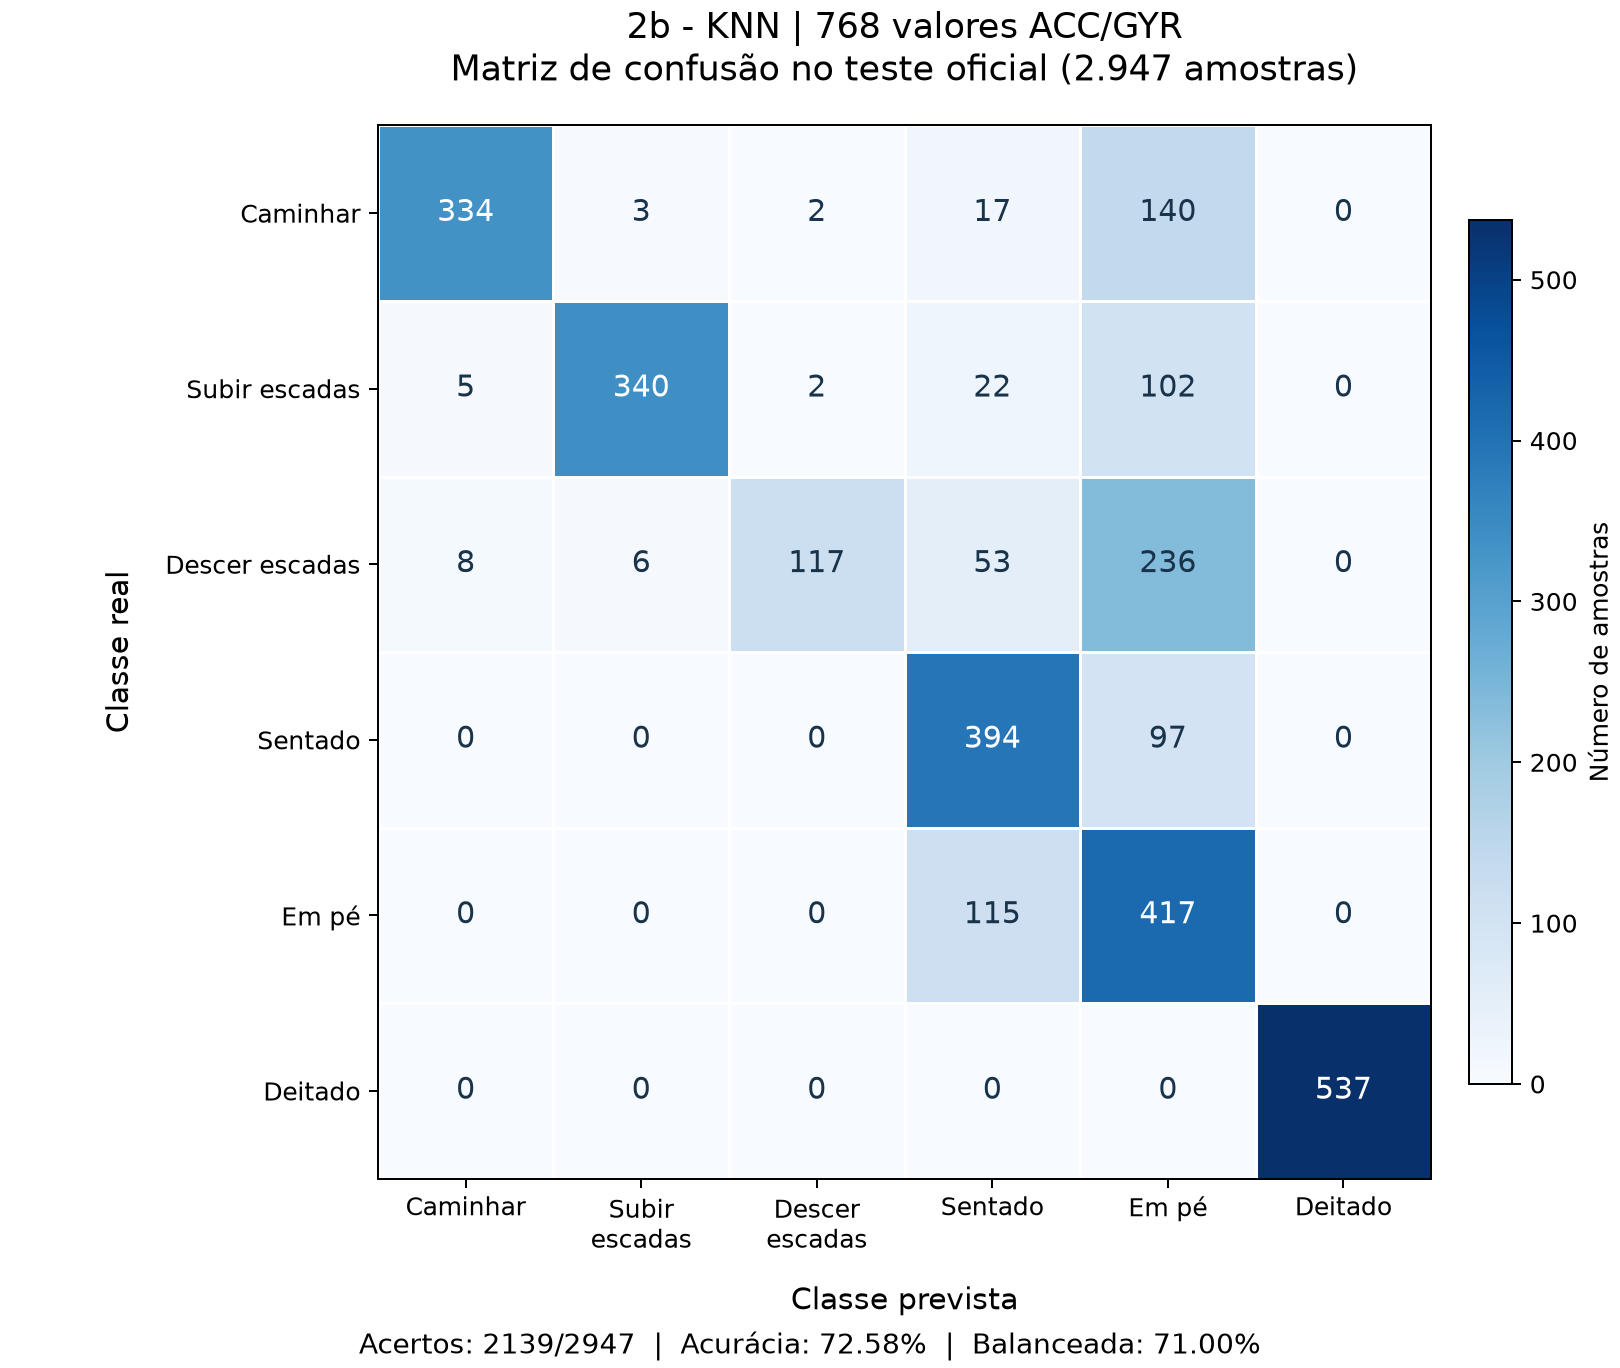

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Linhas: classes reais. Colunas: classes previstas. Valores absolutos.
rotulos = ["Caminhar", "Subir\nescadas", "Descer\nescadas", "Sentado", "Em pé", "Deitado"]
matriz = np.asarray(matriz_confusao_teste, dtype=int)
fig, ax = plt.subplots(figsize=(9, 7.6), layout="constrained")
imagem = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=537)
barra = fig.colorbar(imagem, ax=ax, shrink=0.82, pad=0.03)
barra.set_label("Número de amostras")
ax.set_xticks(range(6), labels=rotulos)
ax.set_yticks(range(6), labels=[r.replace("\n", " ") for r in rotulos])
ax.set_xlabel("Classe prevista", fontsize=12, labelpad=12)
ax.set_ylabel("Classe real", fontsize=12, labelpad=12)
ax.set_title("2b - KNN | 768 valores ACC/GYR\nMatriz de confusão no teste oficial (2.947 amostras)", fontsize=14, pad=18)
for i in range(6):
    for j in range(6):
        ax.text(j, i, str(matriz[i, j]), ha="center", va="center",
                fontsize=12, color="white" if matriz[i, j] > 537 / 2 else "#18334A")
ax.set_xticks(np.arange(-0.5, 6, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 6, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)
acertos = int(np.trace(matriz))
fig.supxlabel(
    f"Acertos: {acertos}/2947  |  Acurácia: {100 * metricas_finais['acuracia_teste']:.2f}%"
    f"  |  Balanceada: {100 * metricas_finais['acuracia_balanceada_teste']:.2f}%", fontsize=11,
)
pasta_figuras = project_root / "results" / "figures"
pasta_figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_figuras / "confusao_2b.png", dpi=180, facecolor="white")
plt.show()
